# Introduction to Matplotlib: 3D Plotting and Animations

**Seong Cho** · ACME Volume 4

**Lab objective:** use Matplotlib's 3D plotting and animation tools, which are useful for visualizing solutions to ODEs and PDEs in dynamics and control problems.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). The lab appears as Lab 1 in the January 2019 edition of the *Volume 4* manual; I did it in September 2018. Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

> **Note.** `vibration.npz` (73 MB) isn't kept in this repo. To rerun Problem 5, download `vibration.npz.gz` from ACME's [data repository](https://github.com/Foundations-of-Applied-Mathematics/Data/tree/master/Animation) and unzip it next to this notebook. The animations I rendered for Problems 3 and 5 in 2018 are also saved here as [`planet_ani.mp4`](planet_ani.mp4) and [`vibration_ani.mp4`](vibration_ani.mp4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import HTML    # [compat]: animations are embedded as HTML

## Figures, axes and lines

The three objects to understand are **figures**, **axes** and **lines**. `plt.figure()` creates the `Figure` (the window shown by `plt.show()`); 3D plotting and animation both need it defined explicitly so it can be modified later. `fig.add_subplot(111)` creates an `Axes`, a space to plot on, and a figure can hold several. `plt.plot()` returns a *list* of `Line2D` objects (`Line3D` on 3D axes), one per curve, so `line, = plt.plot([], [])` unpacks the single line with a trailing comma.

## Animations with `FuncAnimation`

`matplotlib.animation.FuncAnimation` calls a user-defined update function once per frame. The steps:

1. Compute all data to be plotted.
2. Explicitly define the figure object.
3. Define the line objects to be altered dynamically (created with empty data).
4. Write `update(i)`, which takes the frame index, calls `.set_data()` on the lines, and returns a list or tuple of the line objects.
5. Create the `FuncAnimation(fig, update, frames=..., interval=...)` object.
6. Display it with `plt.show()`.

Other parameters: `fargs` (extra arguments to `update`), `interval` (delay between frames in ms), `repeat` (default `True`), `blit` (default `False`). An integer `frames` means `range(frames)`.

> **Note.** Keep a reference to the `FuncAnimation` object. The animation is advanced by a timer, and if no reference is held, Python garbage-collects it and the animation stops.

In this archive the animations are embedded in the notebook with `to_jshtml()`, instead of the interactive `%matplotlib notebook` backend I used in 2018.

In [2]:
%matplotlib inline
# [compat]: was %matplotlib notebook, which doesn't render when executed or on GitHub
plt.rcParams['figure.dpi'] = 72    # Changed: the old inline default resolution, keeps the animations small

The example from the lab: a particle moving along $(\sin t, t^2)$, with its trajectory.

In [3]:
t = np.linspace(0, 2*np.pi, 100)
x = np.sin(t)
y = t**2
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-1.1, 1.1))
ax.set_ylim((0, 40))
particle, = plt.plot([],[], marker='o', color='r')
traj, = plt.plot([],[], color='r', alpha=0.5)

def update(i):
    particle.set_data([x[i]], [y[i]])    # [compat]: set_data() needs sequences
    traj.set_data(x[:i+1], y[:i+1])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(100), interval=25)
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

## Problem 1: Animating a sine wave

> **Problem 1.** Use the FuncAnimation class to animate the function $y = \sin(x + \frac{t}{10})$ where $x \in [0, 2\pi]$, and t ranges from 0 to 100 seconds.

In [4]:
t = np.linspace(0, 100, 100)
x = np.linspace(0, 2*np.pi, 100)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-0, 2*np.pi))
ax.set_ylim((-1, 1))
traj, = plt.plot([],[], color='r')

def update(i):
    traj.set_data(x, np.sin(x + i/10))
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(100), interval=25)
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

## 3D plotting

A 3D axes is created with the extra keyword `projection='3d'` (after importing `Axes3D` from `mpl_toolkits.mplot3d`): `ax = fig.add_subplot(111, projection='3d')`. Plots are then made by calling plot functions such as `ax.plot()` on that axes.

## Problem 2: Orbits of the inner planets

> **Problem 2.** The orbits for Mercury, Venus, Earth, and Mars are stored in the file `orbits.npz`. The file contains four NumPy arrays: `mercury`, `venus`, `earth`, and `mars`. The first column of each array contains the x-coordinates, the second column contains the y-coordinates, and the third column contians the z-coordinates, all relative to the Sun, and expressed in AU (astronomical units, the average distance between Earth and the Sun, approximately 150 million kilometers).
>
> Use `np.load('orbits.npz')` to load the data for the four planets' orbits. Create a 3D plot of the orbits, and compare your results with Figure 1.1.

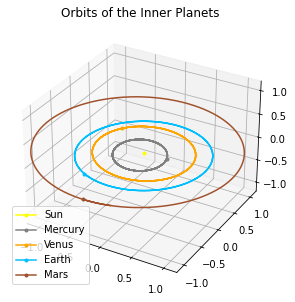

In [5]:
from mpl_toolkits.mplot3d import Axes3D
orbits = np.load('orbits.npz')
mercury_x = orbits["mercury"][:,0]
mercury_y = orbits["mercury"][:,1]
mercury_z = orbits["mercury"][:,2]

venus_x = orbits["venus"][:,0]
venus_y = orbits["venus"][:,1]
venus_z = orbits["venus"][:,2]

earth_x = orbits["earth"][:,0]
earth_y = orbits["earth"][:,1]
earth_z = orbits["earth"][:,2]

mars_x = orbits["mars"][:,0]
mars_y = orbits["mars"][:,1]
mars_z = orbits["mars"][:,2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.set_xlim3d((-1.2, 1.2))
ax.set_ylim3d((-1.2, 1.2))
ax.set_zlim3d((-1.2, 1.2))

plt.plot([0],[0],[0], marker='o', markersize=3, color="yellow", label="Sun")
plt.plot(mercury_x, mercury_y, mercury_z, markevery=[0], marker='o', markersize=3, color='0.5', label="Mercury")
plt.plot(venus_x, venus_y, venus_z, markevery=[0], marker='o', markersize=3, color='orange', label="Venus")
plt.plot(earth_x, earth_y, earth_z, markevery=[0], marker='o', markersize=3, color='deepskyblue', label="Earth")
plt.plot(mars_x, mars_y, mars_z, markevery=[0], marker='o', markersize=3, color='sienna', label="Mars")

plt.legend()
plt.title("Orbits of the Inner Planets")
plt.show()

## 3D animations and saving them

`.set_data()` does not set $z$ values: set $x$ and $y$ with `.set_data()` as before, then $z$ with `.set_3d_properties()`, both inside the update function.

Interactive 3D animations are expensive to render and often choppy, so the lab saves them as video with `FuncAnimation.save()`. Matplotlib has no built-in video encoder; FFmpeg is a lightweight third-party one. Select it with `animation.writer = animation.writers['ffmpeg']`, call `plt.ioff()` to keep the animation from displaying while it renders, then `ani.save('my_animation.mp4')`.

## Problem 3: Animating the orbits

> **Problem 3.** Each row of the arrays in `orbits.npz` gives the position of the planets at a particular time. The arrays have 1400 points in time over a 700 day period (beginning on 2018-5-30). Create a 3D animation of the planet orbits. Display lines for the trajectories of the orbits and points for the current positions of the planets at each point in time. Your update() function will need to return a list of `Line3D` objects, one for each orbit trajectory and one for each planet position marker. Using `animation.save()`, save your animated plot as "planet_ani.mp4".
>
> To display the mp4 video in the Jupyter Notebook, run the following code in a markdown cell:
>
> `<video src="planet_ani.mp4" controls>`

ffmpeg isn't installed here, so the `save()` call is commented out. My 2018 render is saved as [`planet_ani.mp4`](planet_ani.mp4).

In [6]:
from mpl_toolkits.mplot3d import Axes3D
# animation.writer = animation.writers['ffmpeg']    # [compat]: ffmpeg is not installed
plt.ioff()

orbits = np.load('orbits.npz')
mercury_x = orbits["mercury"][:,0]
mercury_y = orbits["mercury"][:,1]
mercury_z = orbits["mercury"][:,2]

venus_x = orbits["venus"][:,0]
venus_y = orbits["venus"][:,1]
venus_z = orbits["venus"][:,2]

earth_x = orbits["earth"][:,0]
earth_y = orbits["earth"][:,1]
earth_z = orbits["earth"][:,2]

mars_x = orbits["mars"][:,0]
mars_y = orbits["mars"][:,1]
mars_z = orbits["mars"][:,2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.set_xlim3d((-1.2, 1.2))
ax.set_ylim3d((-1.2, 1.2))
ax.set_zlim3d((-1.2, 1.2))

ax.plot([0],[0],[0], marker='o', markersize=3, color="yellow", label="Sun")
p1, = plt.plot([], [], [], marker='o', markersize=3, color='0.5', label="Mercury")
t1, = plt.plot([],[],[], color='0.5', alpha=0.5)
p2, = plt.plot([], [], [], marker='o', markersize=3, color='orange', label="Venus")
t2, = plt.plot([],[],[], color='orange', alpha=0.5)
p3, = plt.plot([], [], [], marker='o', markersize=3, color='deepskyblue', label="Earth")
t3, = plt.plot([],[],[], color='deepskyblue', alpha=0.5)
p4, = plt.plot([], [], [], marker='o', markersize=3, color='sienna', label="Mars")
t4, = plt.plot([],[],[], color='sienna', alpha=0.5)

def update(i):
    p1.set_data([mercury_x[i]], [mercury_y[i]])    # [compat]: set_data() needs sequences
    p1.set_3d_properties(mercury_z[i])
    t1.set_data(mercury_x[:i+1], mercury_y[:i+1])
    t1.set_3d_properties(mercury_z[:i+1])
    
    p2.set_data([venus_x[i]], [venus_y[i]])    # [compat]: set_data() needs sequences
    p2.set_3d_properties(venus_z[i])
    t2.set_data(venus_x[:i+1], venus_y[:i+1])
    t2.set_3d_properties(venus_z[:i+1])
    
    p3.set_data([earth_x[i]], [earth_y[i]])    # [compat]: set_data() needs sequences
    p3.set_3d_properties(earth_z[i])
    t3.set_data(earth_x[:i+1], earth_y[:i+1])
    t3.set_3d_properties(earth_z[:i+1])
    
    p4.set_data([mars_x[i]], [mars_y[i]])    # [compat]: set_data() needs sequences
    p4.set_3d_properties(mars_z[i])
    t4.set_data(mars_x[:i+1], mars_y[:i+1])
    t4.set_3d_properties(mars_z[:i+1])

    return p1, t1, p2, t2, p3, t3, p4, t4

ani = animation.FuncAnimation(fig, update, frames=range(0, 1400, 28), interval=25)    # [compat]: every 28th frame, to keep the notebook small
plt.legend()
plt.suptitle("Orbits of the Inner Planets by Seong-Eun Cho")

# ani.save('planet_ani.mp4')    # [compat]: ffmpeg is not installed; my 2018 render is planet_ani.mp4
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]

My 2018 animation: [`planet_ani.mp4`](planet_ani.mp4).

<video src="planet_ani.mp4" controls>

## Surface plotting

Surface plots need a grid: `X, Y = np.meshgrid(x, y)` turns 1D coordinate arrays into 2D arrays that together give the Cartesian coordinates of every grid point. Then `ax.plot_surface(X, Y, Z)` plots a 2D array of heights `Z` of the same shape.

## Problem 4: Bivariate normal density

> **Problem 4.** Make a surface plot of the bivariate normal density function given by:
>
> $$f(\mathbf{x}) = \frac{1}{\sqrt{\det(2\pi\Sigma)}}\exp\left[-\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^{T}\Sigma^{-1}(\mathbf{x}-\boldsymbol{\mu})\right]$$
>
> Where $\mathbf{x} = [x,y]^T \in \mathbb{R}^2$, $\boldsymbol{\mu} = [0,0]^T$ is the mean vector, and: $$\Sigma = \begin{bmatrix} 1 & 3/5 \\ 3/5 & 2 \end{bmatrix}$$ is the covariance matrix.

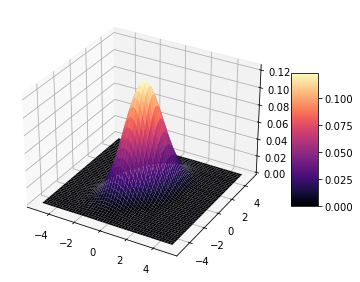

In [7]:
from mpl_toolkits.mplot3d import Axes3D

x = np.linspace(-5,5)
y = np.linspace(-5,5)
X, Y = np.meshgrid(x,y)

cov = np.array([[1, 3/5], [3/5, 2]])
cov_inv = np.linalg.inv(cov)
# Changed: the exponent uses the inverse covariance, as in the spec; this line used cov, not cov_inv
A = cov_inv[0,0]*X**2 + cov_inv[0,1]*X*Y + cov_inv[1,0]*X*Y + cov_inv[1,1]*Y**2
Z = 1/(np.sqrt(np.linalg.det(2*np.pi*cov))) * np.exp((-1/2)*(A))

fig = plt.figure()
ax = fig.add_subplot(111,projection='3d')

# Plot the surface.
surf = ax.plot_surface(X, Y, Z, cmap='magma')
# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()

## Surface animations

The object returned by `.plot_surface()` has no `.set_data()` method. Instead, call `ax.clear()` at each frame and then `ax.plot_surface()` again; the axis limits must be reset after `ax.clear()`.

## Problem 5: Vibrating membrane

> **Problem 5.** Use the data in vibration.npz to produce a surface animation of the solution to the wave equation for an elastic rectangular membrane. The file contains three NumPy arrays: `X`, `Y`, `Z`. `X` and `Y` are meshgrids of shape `(300,200)` corresponding to 300 points in the y-direction and 200 points in the x-direction, all corresponding to a 2x3 rectangle with one corner at the origin. `Z` is of shape `(150,300,200)`, giving the height of the vibrating membrane at each (x,y) point for 150 values of time. In the language of partial differential equations, this is the solution to the following intital/boundary value problem for the wave equation:
>
> $$\begin{aligned}
> &u_{tt} = 6^2(u_{xx}+u_{yy}),\\
> &(x,y) \in [0,2]\times[0,3],\quad t \in [0,5],\\
> &u(t,0,y)=u(t,2,y)=u(t,x,0)=u(t,x,3) = 0,\\
> &u(0,x,y) = xy(2-x)(3-y).
> \end{aligned}$$
>
> Load the data with `np.load('vibration.npz')`. Create a 3D surface animation of the vibrating membrane. Save the animation as `vibration.mp4`.

`vibration.npz` isn't kept in this repo (see the note at the top); the output below was made with it in place. ffmpeg isn't installed here, so the `save()` call is commented out. My 2018 render is saved as [`vibration_ani.mp4`](vibration_ani.mp4).

In [8]:
# animation.writer = animation.writers['ffmpeg']    # [compat]: ffmpeg is not installed
plt.ioff()

data = np.load('vibration.npz')
X = data['X']
Y = data['Y']
Z = data['Z']

fig = plt.figure()
ax = fig.add_subplot(111,projection='3d')

# Plot the surface.
surf = ax.plot_surface(X, Y, Z[0], cmap='coolwarm')
# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)
ax.set_zlim((-4,4))
def update(i):
    ax.clear()
    ax.set_zlim((-4,4))
    surf = ax.plot_surface(X,Y,Z[i], cmap='coolwarm')
    
ani = animation.FuncAnimation(fig, update, frames=range(0, 150, 5), interval=100)    # [compat]: every 5th frame, to keep the notebook small
plt.suptitle("Vibrating membrane by Seong-Eun Cho")
# ani.save('vibration_ani.mp4')    # [compat]: ffmpeg is not installed; my 2018 render is vibration_ani.mp4
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]

My 2018 animation: [`vibration_ani.mp4`](vibration_ani.mp4).

<video src="vibration_ani.mp4" controls>